In [1]:
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt

In [2]:
def bloc(cin, cout):
    """Deux convolutions 3x3 + ReLU (un 'bloc' de U-Net)."""
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.ReLU(),
        nn.Conv2d(cout, cout, 3, padding=1), nn.ReLU())

class UNet(nn.Module):
    def __init__(self, base=16):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        # Chemin contractant : les canaux doublent à chaque étage
        self.d1 = bloc(1, base)
        self.d2 = bloc(base, base*2)
        self.d3 = bloc(base*2, base*4)
        # Point le plus bas
        self.bas = bloc(base*4, base*8)
        # Chemin expansif : up-convolution, puis concaténation (skip connection)
        self.up3 = nn.ConvTranspose2d(base*8, base*4, 2, stride=2)
        self.u3  = bloc(base*8, base*4)
        self.up2 = nn.ConvTranspose2d(base*4, base*2, 2, stride=2)
        self.u2  = bloc(base*4, base*2)
        self.up1 = nn.ConvTranspose2d(base*2, base, 2, stride=2)
        self.u1  = bloc(base*2, base)
        self.fin = nn.Conv2d(base, 1, 1)      # convolution 1x1 finale

    def forward(self, x):
        c1 = self.d1(x)                        # descente
        c2 = self.d2(self.pool(c1))
        c3 = self.d3(self.pool(c2))
        b  = self.bas(self.pool(c3))
        x = self.u3(torch.cat([c3, self.up3(b)], dim=1))   # montée + skip connection
        x = self.u2(torch.cat([c2, self.up2(x)], dim=1))
        x = self.u1(torch.cat([c1, self.up1(x)], dim=1))
        return self.fin(x)

model = UNet()
print(model(torch.zeros(1, 1, 64, 64)).shape)   # doit afficher torch.Size([1, 1, 64, 64])

torch.Size([1, 1, 64, 64])


In [3]:
#le modèle U-Net (version simplifiée)

def bloc(cin, cout):
    """Deux convolutions 3x3 + ReLU (un 'bloc' de U-Net)."""
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.ReLU(),
        nn.Conv2d(cout, cout, 3, padding=1), nn.ReLU())

class UNet(nn.Module):
    def __init__(self, base=16):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        # Chemin contractant : les canaux doublent à chaque étage
        self.d1 = bloc(1, base)
        self.d2 = bloc(base, base*2)
        self.d3 = bloc(base*2, base*4)
        # Point le plus bas
        self.bas = bloc(base*4, base*8)
        # Chemin expansif : up-convolution, puis concaténation (skip connection)
        self.up3 = nn.ConvTranspose2d(base*8, base*4, 2, stride=2)
        self.u3  = bloc(base*8, base*4)
        self.up2 = nn.ConvTranspose2d(base*4, base*2, 2, stride=2)
        self.u2  = bloc(base*4, base*2)
        self.up1 = nn.ConvTranspose2d(base*2, base, 2, stride=2)
        self.u1  = bloc(base*2, base)
        self.fin = nn.Conv2d(base, 1, 1)      # convolution 1x1 finale

    def forward(self, x):
        c1 = self.d1(x)                        # descente
        c2 = self.d2(self.pool(c1))
        c3 = self.d3(self.pool(c2))
        b  = self.bas(self.pool(c3))
        x = self.u3(torch.cat([c3, self.up3(b)], dim=1))   # montée + skip connection
        x = self.u2(torch.cat([c2, self.up2(x)], dim=1))
        x = self.u1(torch.cat([c1, self.up1(x)], dim=1))
        return self.fin(x)

model = UNet()
print(model(torch.zeros(1, 1, 64, 64)).shape)   # doit afficher torch.Size([1, 1, 64, 64])

torch.Size([1, 1, 64, 64])


In [4]:
#données synthétiques
def fabriquer_image(taille=64):
    yy, xx = np.mgrid[:taille, :taille]
    masque = np.zeros((taille, taille), np.float32)
    for _ in range(np.random.randint(2, 5)):          # 2 à 4 disques
        cy, cx = np.random.randint(10, taille-10, 2)
        r = np.random.randint(5, 10)
        masque[(yy-cy)**2 + (xx-cx)**2 < r**2] = 1
    image = masque*0.6 + 0.2 + np.random.normal(0, 0.1, masque.shape)
    return image.astype(np.float32), masque

def fabriquer_jeu(n):
    paires = [fabriquer_image() for _ in range(n)]
    X = torch.tensor(np.stack([p[0] for p in paires]))[:, None]   # (n, 1, 64, 64)
    Y = torch.tensor(np.stack([p[1] for p in paires]))[:, None]
    return X, Y

np.random.seed(0); torch.manual_seed(0)
X_train, Y_train = fabriquer_jeu(200)
X_test,  Y_test  = fabriquer_jeu(50)

époque  5 | perte = 0.0233
époque 10 | perte = 0.0058
époque 15 | perte = 0.0033
époque 20 | perte = 0.0035
époque 25 | perte = 0.0024
époque 30 | perte = 0.0022


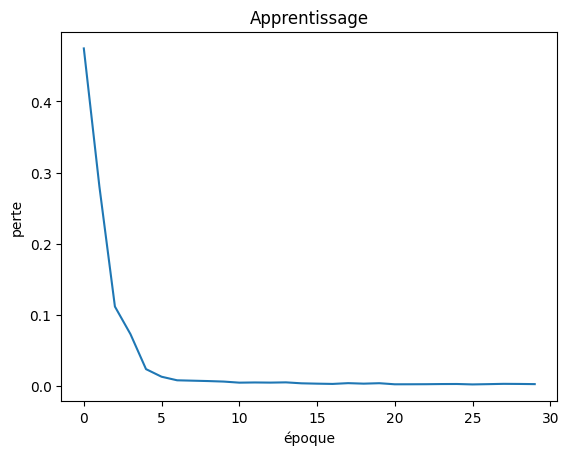

In [5]:
#entraînement
perte_fn = nn.BCEWithLogitsLoss()                   # entropie croisée binaire
optim = torch.optim.Adam(model.parameters(), lr=1e-3)
pertes = []

for epoque in range(30):
    ordre = torch.randperm(len(X_train))
    for i in range(0, len(X_train), 16):            # mini-batchs de 16 images
        idx = ordre[i:i+16]
        perte = perte_fn(model(X_train[idx]), Y_train[idx])
        optim.zero_grad(); perte.backward(); optim.step()
    pertes.append(perte.item())
    if (epoque+1) % 5 == 0:
        print(f"époque {epoque+1:2d} | perte = {perte.item():.4f}")

plt.plot(pertes); plt.xlabel("époque"); plt.ylabel("perte"); plt.title("Apprentissage"); plt.show()

IoU moyen sur le test : 0.994


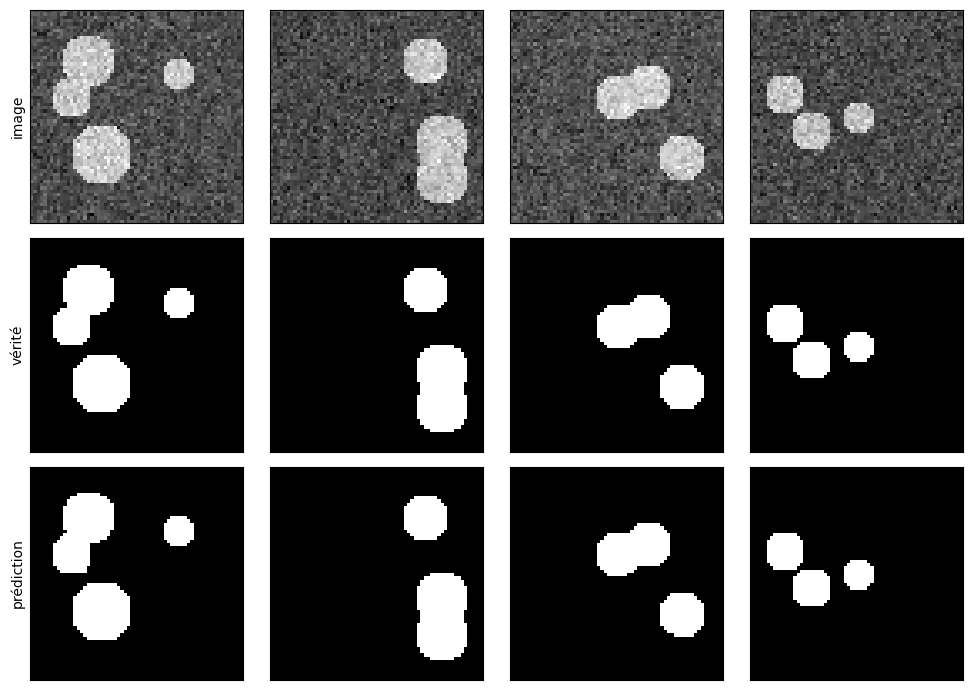

In [6]:
#évaluation (IoU) et visualisation

model.eval()
with torch.no_grad():
    pred = (torch.sigmoid(model(X_test)) > 0.5).float()

inter = (pred * Y_test).sum(dim=(1, 2, 3))
union = ((pred + Y_test) > 0).float().sum(dim=(1, 2, 3))
print(f"IoU moyen sur le test : {(inter/union).mean().item():.3f}")

fig, ax = plt.subplots(3, 4, figsize=(10, 7))
for k in range(4):
    ax[0, k].imshow(X_test[k, 0], cmap="gray"); ax[1, k].imshow(Y_test[k, 0], cmap="gray")
    ax[2, k].imshow(pred[k, 0], cmap="gray")
for a, titre in zip(ax[:, 0], ["image", "vérité", "prédiction"]): a.set_ylabel(titre)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()